# Limpieza de señal ECG

Lee los `.py` del proyecto (`leer_senal.py`, `filtros.py`), agarra la señal de un CSV y la limpia (pasa-altos 0,5 Hz + notch 50 Hz).

In [1]:
# --- Entorno: agrega la raíz del proyecto al path para poder importar src ---
import sys, os
sys.path.append(os.path.abspath(".."))  # nootebooks/ -> raíz del proyecto

# --- Librerías ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

# --- Funciones propias, directo desde src ---
from src import obtener_señal as obt
from src import filtraado as flt

In [2]:
FS = 480.0  # Hz (ver justificación en el informe)

# Ruta al CSV con la señal a limpiar
ruta_csv = "../data/ecg_data_post.csv"  # cambiar por el archivo que corresponda
ruta_csv_limpio = "../results/ecg_data_post_clean.csv"

In [44]:
col, senal = obt.agarrar_senal(ruta_csv)
recorte = int(0.5 * FS)
senal = senal[recorte:]
print(f"Columna: {col}  |  muestras: {len(senal)}  |  duración: {len(senal)/FS:.1f} s")

Columna: Sample  |  muestras: 86360  |  duración: 179.9 s


In [56]:
senal_hp = flt.filtro_pasa_altos(senal, FS)                    # fc=0.5Hz
senal_notch = flt.filtro_notch(senal_hp, FS)                   # 50Hz
senal_sin_deriva = flt.resta_linea_base_mediana(senal_notch, FS)  # nueva: saca la deriva que quedaba
senal_final = flt.promedio_movil(senal_sin_deriva, FS, ventana_ms=20)

AttributeError: module 'src.filtraado' has no attribute 'resta_linea_base_mediana'

In [6]:
import pandas as pd

pd.DataFrame({col: senal_notch}).to_csv(ruta_csv_limpio, index=False)
print(f"Guardado: {ruta_csv_limpio}")

Guardado: ../results/ecg_data_post_clean.csv


## Comparación cruda vs. limpia

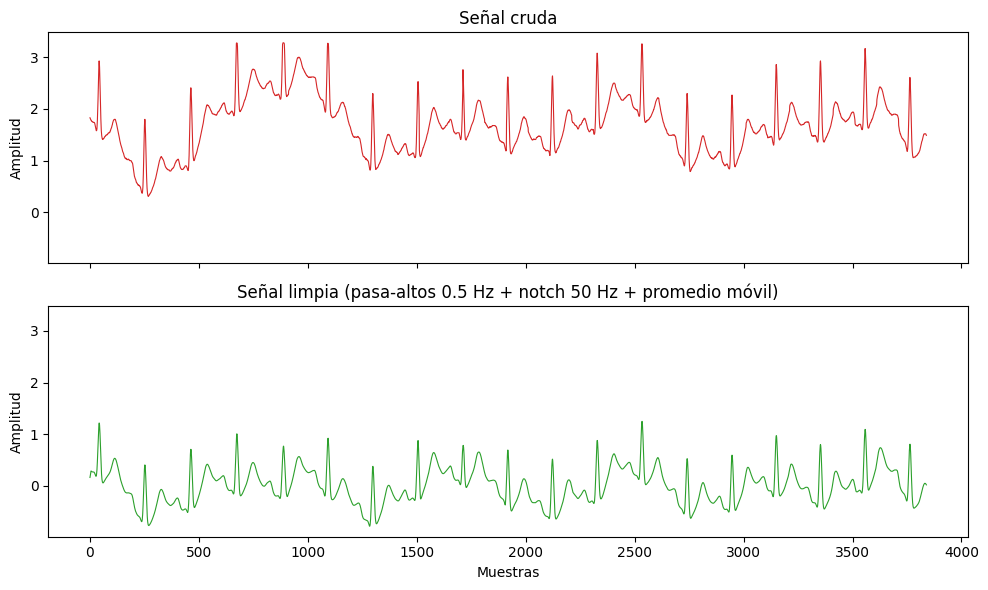

In [52]:
import numpy as np
import matplotlib.pyplot as plt

segundos = 8
n = int(segundos * FS)
muestras = np.arange(n)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
axes[0].plot(muestras, senal[:n], color="tab:red", linewidth=0.8)
axes[0].set_title("Señal cruda")
axes[0].set_ylabel("Amplitud")

axes[1].plot(muestras, senal_limpia[:n], color="tab:green", linewidth=0.8)
axes[1].set_title("Señal limpia (pasa-altos 0.5 Hz + notch 50 Hz + promedio móvil)")
axes[1].set_ylabel("Amplitud")
axes[1].set_xlabel("Muestras")

plt.tight_layout()
plt.show()